In [8]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from dotenv import load_dotenv
import os

In [5]:
load_dotenv()

True

In [2]:
apikey = os.getenv("GROQ_API_KEY")

In [6]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)

In [7]:
class LLMState(TypedDict):
    question : str
    answer : str

In [13]:
def llmqa(state:LLMState)->LLMState:
    question = state['question']
    prompt = f"answer the following question {question}"

    answer = llm.invoke(prompt).content
    state['answer'] = answer
    return state

In [14]:
graph = StateGraph(LLMState)

graph.add_node("llmqa",llmqa)

graph.add_edge(START,"llmqa")
graph.add_edge("llmqa",END)


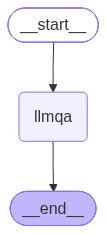

In [15]:
workflow = graph.compile()
workflow

In [16]:
intial_State = {"question":"who is virat kohli"}
final_state = workflow.invoke(intial_State)
final_state

{'question': 'who is virat kohli',
 'answer': 'Virat Kohli is an Indian international cricketer widely regarded as one of the greatest batsmen of his generation. Born on 5\u202fNovember\u202f1988 in Delhi, he rose through the ranks to become the captain of India’s national teams across all formats (ODI, T20I, and Test) and led the side to numerous historic victories, including a series win in Australia (2018–19) and a record‑breaking 5‑for‑1 Test series in England (2018). Known for his aggressive batting style, consistency, and fitness, Kohli has amassed over 12,000 runs in ODIs and 7,000+ in Tests, earning multiple ICC awards and the ICC Cricketer of the Year title. He is also a prominent philanthropist and brand ambassador, and he continues to be a central figure in Indian cricket.'}